In [5]:
DN = ['SDSS J000720.77+200721.6', 'J001107.26+303235.9', 'J001153.08-064739.2',
'J001158.28+315543.7', 'J001231.54+280011.1', 'J001538.25+263656.7',
'J002049.51+280020.2', 'J002243.55+061002.7', 'J002728.00-010828.5',
'J002910.96+324125.8', 'J003151.76+202051.0', 'J003153.46+084118.5',
'J003203.62+314510.4', 'J003459.90+273619.0', 'J0813+4528',
'J0032+3145', 'J1610−0102', 'J1028+2148', 'J0058-0107', 'J0804+5103',
'J0843+2751', 'J0904+4402', 'J1035+0551', 'J1057+2759',
'J1216+0520', 'J1255+2642', 'J1433+1011', 'J1435+2336',
'J1507+5230', 'J2131-0039', 'J2304+0625', 'J000014.74+255603.1',
'J001231.54+280011.1', 'J002910.96+324125.8', 'J004849.86+332832.9',
'J005421.90+334815.7', 'J012212.21+075546.8', 'J014121.21+062007.6',
'J015253.39-004350.4', 'J015803.40+282303.6', 'J023046.26-004531.1',
'J024215.05-011054.4', 'J072827.34+330741.6', 'J080249.06+363716.4',
'J080625.73+343244.4', 'J081017.41+262238.3', 'J081520.83+335634.1',
'J084228.13+462334.4', 'J090947.82+110637.0', 'J091107.84+260617.3',
'J093130.75+335651.2', 'J101335.56+393826.3', 'J101723.18+375343.4',
'J104521.19+362433.0', 'J115419.05+575751.1', 'J121015.61+351334.4',
'J123717.98+365535.2', 'J133816.44+371639.8', 'J152603.67+382216.4',
'J160813.59+301952.2', 'J161853.16+303845.5', 'J163620.62+472442.4',
'J171016.94+403127.5', 'J211652.28+014144.3', 'J212406.75+010029.8',
'J213040.11-001319.1', 'J220818.52+135330.0', 'J220935.78-001332.5',
'J221333.38+245059.3', 'J221900.24+201831.1', 'J223212.79+260725.1',
'J223352.56+225913.4', 'J223623.52+323913.1', 'J225613.53+191132.9',
'J225926.51+223902.4', 'J230319.85+274736.0', 'J232113.45+251822.3',
'J232553.47+011527.3', 'J233705.01+314149.4', 'J235131.68+270907.7',
'J235603.71+001833.3']

In [6]:
from astroquery.simbad import Simbad

nombres_simbad = []
for nombre in DN:
    if not nombre.startswith("SDSS"):
        nombres_simbad.append(f"SDSS {nombre}")
    else:
        nombres_simbad.append(nombre)


Simbad.add_votable_fields('plx_value', 'plx_err', 'otype') 

print("Consultando a SIMBAD toda la lista de una vez...")

try:
    resultado = Simbad.query_objects(nombres_simbad)
    
    if resultado is not None:
        print("\n¡Consulta exitosa! Aquí están los resultados:\n")

        resultado_limpio = resultado['main_id', 'OTYPE', 'PLX_VALUE', 'PLX_ERR']
        print(resultado_limpio)
    else:
        print("SIMBAD no encontró ninguno de los objetos de la lista.")
        
except Exception as e:
    print(f"Ocurrió un error al consultar SIMBAD: {e}")

Consultando a SIMBAD toda la lista de una vez...

¡Consulta exitosa! Aquí están los resultados:


Ocurrió un error al consultar SIMBAD: 'OTYPE'


In [9]:
from astroquery.gaia import Gaia
from astropy.table import Table
import numpy as np

t = Table()
t["id_sdss"] = resultado['main_id']  
t["ra"] = resultado['ra']
t["dec"] = resultado['dec']

mask = (~np.isnan(t["ra"])) & (~np.isnan(t["dec"]))
t_limpia = t[mask]  

job = Gaia.launch_job_async(
    query="""
    SELECT 
        t.id_sdss,
        g.source_id,
        g.ra AS gaia_ra,
        g.dec AS gaia_dec,
        g.parallax,
        g.parallax_error
    FROM gaiadr3.gaia_source AS g
    JOIN tap_upload.my_table AS t
    ON CONTAINS(
        POINT('ICRS', g.ra, g.dec),
        CIRCLE('ICRS', t.ra, t.dec, 2.0/3600.0)
    ) = 1
    """,
    upload_resource=t_limpia,
    upload_table_name="my_table"
)

#
resultados_gaia = job.get_results()

print("\n¡Cross-match completado!")
print(resultados_gaia)

Subiendo 44 objetos a Gaia para el cross-match...


KeyboardInterrupt: 

In [4]:
resultados_gaia

id_sdss,source_id,gaia_ra,gaia_dec,parallax,parallax_error
,,deg,deg,mas,mas
object,int64,float64,float64,float64,float32
SDSS J220935.78-001332.5,2678822818216797056,332.3991707197885,-0.22579002912619095,--,--
CRTS J001158.3+315544,2861949606559861120,2.99285174339145,31.928795024784876,--,--
CRTS J003203.6+314510,2859621764350006784,8.015113007482833,31.752879462008057,1.0692600051187582,0.20847496
SDSS J004849.86+332832.9,361363704879572736,12.207798151100455,33.47579693075829,1.6857543672138298,0.57802635
CRTS J003500.0+273620,2857545615813275136,8.749594989045569,27.605286331592595,-0.5135818552577348,0.9211383
CRTS J001538.3+263657,2856493142666940544,3.9094423670725256,26.615733893043778,1.8044274787250085,0.10654354
SDSS J002049.51+280020.2,2857063063352792320,5.206317582518205,28.005620594914312,3.118486987424927,0.44086662
SDSS J014121.21+062007.6,2562434457240098432,25.338341406673262,6.33536687315115,--,--


In [213]:
from astroquery.vizier import Vizier
v = Vizier(row_limit=-1, columns=['**'])# para obtener todas las filas

# Ver los distintos catalogos
catalog_list = v.find_catalogs("Ritter Kolb")
result = v.get_catalogs("B/cb")
# para ver el nombre de las columnas de la primera fila
table = result[0]
table

recno,Name,whoswho,AltName,fp,RAJ2000,DEJ2000,epos,Type1,u_Type1,Type2,u_Type2,Type3,u_Type3,Type4,u_Type4,l_mag1,mag1,f_mag1,l_mag2,mag2,f_mag2,l_mag3,mag3,f_mag3,l_mag4,mag4,f_mag4,T1,T2,Orb.Per,u_Orb.Per,2.__Per,u_2.__Per,3.__Per,f_3.__Per,4.__Per,u_4.__Per,EB,u_EB,SB,u_SB,SpType2,SpType1,f_M1/M2,M1/M2,u_M1/M2,e_M1/M2,l_Incl,Incl,u_Incl,e_Incl,l_M1,M1,u_M1,e_M1,l_M2,M2,u_M2,e_M2,Refs,Simbad
,,,,,,,arcsec,,,,,,,,,,mag,,,mag,,,mag,,,mag,,d,d,d,,d,,s,,s,,,,,,,,,,,,,deg,,deg,,solMass,,solMass,,solMass,,solMass,,
int32,str12,str1,str12,str1,str10,str9,str1,str2,str1,str2,str1,str2,str1,str2,str1,str1,float32,str1,str1,float32,str1,str1,float32,str1,str1,float32,str1,str5,str5,float64,str1,float32,str1,float64,str1,float64,str1,str1,str1,uint8,str1,str7,str7,str1,float32,str1,float32,str1,float32,str1,float32,str1,float32,str1,float32,str1,float32,str1,float32,str4,str6
1,V1017 Sgr,*,N Sgr 1919,,18 32 04.5,-29 23 12,1,Nb,,DN,,,,,,,13.7,,,--,,,7.2,,,10.7,,,,5.714000,,--,,--,,--,,,,1,,G5/3p,,,--,,--,,--,,--,,--,,--,,--,,--,Refs,Simbad
2,MR Vel,*,0925-4758,,09 25 45.9,-47 58 18,1,SS,,,,,,,,,17.0,,,17.4,,,--,,,--,,,,4.028782,,--,,--,,--,,,,1,,,,,--,,--,,55.0,,10.0,,--,,--,,--,,--,Refs,Simbad
3,V630 Cas,*,N Cas 1950,,23 48 51.9,+51 27 39,1,DN,,,,,,,,,16.2,,,16.8,,,14.2,,,--,,,,2.563870,,--,,--,,--,,,,2,,K4-5,,,5.50,,0.60,,72.5,,5.5,,1.010,,0.130,,0.180,,0.020,Refs,Simbad
4,EQ CMa,*,,,06 48 51.6,-16 18 03,1,CV,?,,,,,,,,11.9,p,,12.9,p,,--,,,--,,,,2.291500,,--,,--,,--,,1,,--,,,,,--,,--,,--,,--,,--,,--,,--,,--,Refs,Simbad
5,GK Per,*,N Per 1901,,03 31 12.0,+43 54 16,1,Na,,DN,,IP,,,,,12.8,,,13.7,,,0.2,,,10.2,,1060,,1.996803,,--,,351.332,,--,,,,2,,K1/4,,,2.10,,0.80,<,73.0,,--,>,0.870,,0.240,>,0.480,,0.320,Refs,Simbad
6,HV Cet,*,N Cet 2008,,03 05 58.5,+05 47 14,4,N,,,,,,,,,18.5,g,,--,,,14.2,,,--,,,,1.772000,,--,,--,,--,,,,--,,,,,--,,--,,--,,--,,--,,--,,--,,--,Refs,Simbad
7,J2044-0459,*,,,20 44 48.9,-04 59 29,1,DN,,UG,,,,,,,16.7,,,--,,,14.3,,,--,,,,1.680000,,--,,--,,--,,,,2,,K4-5,,,2.80,,0.70,,--,,--,,--,,--,,--,,--,Refs,Simbad
8,V5589 Sgr,*,N Sgr 2012,,17 45 28.0,-23 05 23,1,Na,,,,,,,,,17.0,I,,--,,,9.6,,,--,,,,1.592300,,--,,--,,--,,1,,--,,,,,--,,--,,--,,--,,--,,--,,--,,--,Refs,Simbad


In [73]:
from astropy.coordinates import SkyCoord
import astropy.units as u

coords_gaia = SkyCoord(
    ra=resultados_gaia["gaia_ra"].data* u.deg,
    dec=resultados_gaia["gaia_dec"].data* u.deg
)

coords_ritter = SkyCoord(
    DN_list["RAJ2000"],
    DN_list["DEJ2000"],
    unit=(u.hourangle, u.deg)
)

idx, d2d, _ = coords_gaia.match_to_catalog_sky(coords_ritter)

In [81]:
resultados_gaia["ritter_idx"] = idx
resultados_gaia["sep_arcsec"] = d2d.to(u.arcsec)
mask = d2d < 2 * u.arcsec
resultados_gaia["tipo_CV"] = None
resultados_gaia["tipo_DN"] = None
resultados_gaia["P_orb"] = np.nan

resultados_gaia["tipo_CV"][mask] = DN_list["Type1"][idx[mask]]
resultados_gaia["tipo_DN"][mask] = DN_list["Type2"][idx[mask]]
resultados_gaia["P_orb"][mask] = DN_list["Orb.Per"][idx[mask]]

In [83]:
resultados_gaia.remove_column("parallax_error")
resultados_gaia.remove_column("ritter_idx")
resultados_gaia.remove_column("sep_arcsec")

In [97]:
resultados_gaia
mask = ~resultados_gaia["parallax"].mask
tabla_limpia = resultados_gaia[mask]

In [153]:
tabla_limpia = tabla_limpia[
    ['id_sdss', "source_id", "gaia_ra", "gaia_dec",'tipo_CV', 'tipo_DN' , "P_orb", 'parallax']]

In [162]:
tabla_limpia_pepe = tabla_limpia[~np.isnan(tabla_limpia["P_orb"])]

In [164]:
df = tabla_limpia_pepe.to_pandas()

In [165]:
df

,id_sdss,source_id,gaia_ra,gaia_dec,tipo_CV,tipo_DN,P_orb,parallax
0,V* V402 And,2861506395998660096,2.780253,30.543308,DN,SU,0.062100,1.580697
1,2MASS J00115308-0647392,2443219535337313280,2.971220,-6.794183,DN,UG,0.100281,2.065791
2,CRTS J001538.3+263657,2856493142666940544,3.909442,26.615734,DN,SU,0.070000,1.804427


In [183]:
df = df.rename(columns={
    "id_sdss": "name",
    "gaia_ra": "ra",
    "gaia_dec": "dec",
    "tipo_CV": "Type1",
    "tipo_DN": "Type2",
    "P_orb": "Porb"
})

In [184]:
df

,name,source_id,ra,dec,Type1,Type2,Porb,parallax
0,V* V402 And,2861506395998660096,2.780253,30.543308,DN,SU,0.062100,1.580697
1,2MASS J00115308-0647392,2443219535337313280,2.971220,-6.794183,DN,UG,0.100281,2.065791
2,CRTS J001538.3+263657,2856493142666940544,3.909442,26.615734,DN,SU,0.070000,1.804427


In [100]:
import pandas as pd
tabla_final = pd.read_csv('tabla_final.csv')

In [104]:
custom = Simbad()
custom.add_votable_fields("ids")

def query_simbad(ra, dec, radius=2):
    coord = SkyCoord(ra=ra*u.deg, dec=dec*u.deg)
    
    result = custom.query_region(coord, radius=radius*u.arcsec)
    
    if result is None:
        return None, None
    
    main_id = result["main_id"][0]
    ids = result["ids"][0]
    
    return main_id, ids

In [105]:
names = []
all_ids = []

for i in range(len(tabla_final)):
    ra = tabla_final["ra"][i]
    dec = tabla_final["dec"][i]
    
    main_id, ids = query_simbad(ra, dec)
    
    names.append(main_id)
    all_ids.append(ids)

In [106]:
tabla_final["name"] = names

In [108]:
ids = ",".join(map(str, tabla_final["source_id"]))

query = f"""
SELECT source_id, parallax
FROM gaiadr3.gaia_source
WHERE source_id IN ({ids})
"""

job = Gaia.launch_job(query)
gaia_data = job.get_results()

In [114]:
print(type(gaia_data))

<class 'astropy.table.table.Table'>


In [116]:
from astropy.table import join

gaia_df = gaia_data.to_pandas()

tabla_final = tabla_final.merge(
    gaia_df[["source_id", "parallax"]],
    on="source_id",
    how="left"
)

In [120]:
tabla_final = tabla_final[
    ['name', "source_id", "ra", "dec",'Type1', 'Type2' , "Porb", 'parallax']]

In [123]:
print(tabla_final["Type1"].unique())

['DN' 'NL' 'CV' 'AC' 'Na']


In [125]:
excluir = ["NL", "CV", "AC", "Na"]

tabla_filtrada = tabla_final[
    ~tabla_final["Type1"].str.contains("|".join(excluir), na=False)
]

In [128]:
print(tabla_filtrada['Type2'].unique())

['UG' 'SU' nan 'BD' 'ZC' 'ER' 'IP' 'WZ' 'SW' 'ZZ' 'NS' 'NL']


In [137]:
excluir = ["BD", "ER", "IP", "WZ", "SW", "ZZ", "NS", "NL","nan"]

tabla_filtrada_xddd = tabla_filtrada[
    ~tabla_filtrada["Type2"].str.contains("|".join(excluir), na=False)
]

In [139]:
print(tabla_filtrada_xddd['Type2'].unique())

['UG' 'SU' nan 'ZC']


In [140]:
tabla_filtrada_puchis = tabla_filtrada_xddd.dropna(subset=["Type2"])

In [142]:
print(tabla_filtrada_puchis['Type2'].unique())

['UG' 'SU' 'ZC']


In [150]:
tabla_basta = tabla_filtrada_puchis.dropna(subset=["parallax"])

In [151]:
tabla_basta

,name,source_id,ra,dec,Type1,Type2,Porb,parallax
0,V* U Gem,674214551557961984,118.771670,22.001222,DN,UG,0.176906,10.704757
1,V* RU LMi,747013839203280000,150.531120,33.850048,DN,UG,0.251000,1.060045
2,V* SS LMi,747774769969350528,158.522601,31.135618,DN,SU,0.056640,0.734795
4,V* EX Dra,2258357545848389888,271.059771,67.903456,DN,UG,0.209937,4.146697
5,V* AB Dra,2291308397504739968,297.277042,77.739769,DN,UG,0.152000,2.494294
...,...,...,...,...,...,...,...,...
301,V* V1195 Oph,4127862801571324416,255.090279,-20.892733,DN,SU,0.065000,0.581352
303,V* PQ Aql,4304999622372178048,298.277805,12.983545,DN,UG,0.246750,0.731872
305,V* PR Her,4610221438876442368,272.018554,38.771412,DN,SU,0.054220,1.749925
306,V* QZ Lib,6318149711371454464,234.066746,-8.652398,DN,SU,0.063300,5.022558


In [185]:
xd = pd.concat([tabla_basta, df], axis=0).reset_index(drop=True)

In [186]:
xd

,name,source_id,ra,dec,Type1,Type2,Porb,parallax
0,V* U Gem,674214551557961984,118.771670,22.001222,DN,UG,0.176906,10.704757
1,V* RU LMi,747013839203280000,150.531120,33.850048,DN,UG,0.251000,1.060045
2,V* SS LMi,747774769969350528,158.522601,31.135618,DN,SU,0.056640,0.734795
3,V* EX Dra,2258357545848389888,271.059771,67.903456,DN,UG,0.209937,4.146697
4,V* AB Dra,2291308397504739968,297.277042,77.739769,DN,UG,0.152000,2.494294
...,...,...,...,...,...,...,...,...
261,V* QZ Lib,6318149711371454464,234.066746,-8.652398,DN,SU,0.063300,5.022558
262,V* VY Aqr,6896767366186700416,318.038735,-8.827074,DN,SU,0.063090,7.052574
263,V* V402 And,2861506395998660096,2.780253,30.543308,DN,SU,0.062100,1.580697
264,2MASS J00115308-0647392,2443219535337313280,2.971220,-6.794183,DN,UG,0.100281,2.065791


In [189]:
df_cac = caca.drop_duplicates(subset=["name"])

In [219]:
df_s = pd.read_csv('mi_catalogo_CVs.csv')
df_s

,name,source_id,ra,dec,Type1,Type2,Porb,parallax
0,V* U Gem,674214551557961984,118.771670,22.001222,DN,UG,0.176906,10.704757
1,V* RU LMi,747013839203280000,150.531120,33.850048,DN,UG,0.251000,1.060045
2,V* SS LMi,747774769969350528,158.522601,31.135618,DN,SU,0.056640,0.734795
3,V* EX Dra,2258357545848389888,271.059771,67.903456,DN,UG,0.209937,4.146697
4,V* AB Dra,2291308397504739968,297.277042,77.739769,DN,UG,0.152000,2.494294
...,...,...,...,...,...,...,...,...
261,V* QZ Lib,6318149711371454464,234.066746,-8.652398,DN,SU,0.063300,5.022558
262,V* VY Aqr,6896767366186700416,318.038735,-8.827074,DN,SU,0.063090,7.052574
263,V* V402 And,2861506395998660096,2.780253,30.543308,DN,SU,0.062100,1.580697
264,2MASS J00115308-0647392,2443219535337313280,2.971220,-6.794183,DN,UG,0.100281,2.065791


In [216]:
tablas_deseadas = ['Name', 'RAJ2000', 'DEJ2000', 'Incl']
tabla_limpia = table[tablas_deseadas]

In [235]:
df_ritter = tabla_limpia.to_pandas()

coords_csv = SkyCoord(ra=df_s['ra'].values * u.deg, dec=df_s['dec'].values * u.deg, frame='icrs')
coords_ritter = SkyCoord(df_ritter['RAJ2000'].astype(str), df_ritter['DEJ2000'].astype(str), unit=(u.hourangle, u.deg), frame='icrs')

idx, d2d, d3d = coords_csv.match_to_catalog_sky(coords_ritter)

max_sep = 2 * u.arcsec
match_valido = d2d < max_sep

df_s['incl'] = float('nan')

df_s.loc[match_valido, 'Incl'] = df_ritter.iloc[idx[match_valido]]['Incl'].values


In [238]:
df_s = df_s.drop('distancia_match_arcsec', axis=1)

In [239]:
df_s = df_s.drop('incl', axis= 1)

In [241]:
df_s.to_csv('Catalogue_DN.csv', index = False)

In [9]:
import pandas as pd
df = pd.read_csv('table_irsa_DN.csv')
df_ztf = df[df['filtercode'] != 'zi']

,cntr_01,pang_x,name_01,source_id_01,ra_01,dec_01,type1_01,type2_01,porb_01,parallax_01,incl_01,oid,ra,dec,filtercode,ngoodobs,ngoodobsrel,nobs,nobsrel
0,1,-135.454716,V* U Gem,674214551557961984,118.771670,22.001222,DN,UG,0.176906,10.704757,NaN,1612107100003449,118.771647,22.001200,zg,60,49,76,63
1,1,-147.701613,V* U Gem,674214551557961984,118.771670,22.001222,DN,UG,0.176906,10.704757,NaN,1612207100004338,118.771646,22.001186,zr,113,93,181,160
2,2,19.100411,V* RU LMi,747013839203280000,150.531120,33.850048,DN,UG,0.251000,1.060045,NaN,1710204300010174,150.531129,33.850070,zr,121,83,135,97
3,2,53.861695,V* RU LMi,747013839203280000,150.531120,33.850048,DN,UG,0.251000,1.060045,NaN,1709201400001039,150.531153,33.850068,zr,107,81,120,93
4,2,-6.640109,V* RU LMi,747013839203280000,150.531120,33.850048,DN,UG,0.251000,1.060045,NaN,667210400010495,150.531115,33.850085,zr,932,815,1031,895
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1194,265,26.193039,2MASS J00115308-0647392,2443219535337313280,2.971220,-6.794183,DN,UG,0.100281,2.065791,59.0,345216100013407,2.971234,-6.794154,zr,400,337,485,390
1195,266,43.460042,CRTS J001538.3+263657,2856493142666940544,3.909442,26.615734,DN,SU,0.070000,1.804427,NaN,600209300005158,3.909455,26.615746,zr,1486,1210,1564,1287
1196,266,86.571330,CRTS J001538.3+263657,2856493142666940544,3.909442,26.615734,DN,SU,0.070000,1.804427,NaN,1645101400001881,3.909465,26.615735,zg,112,80,115,82
1197,266,84.099600,CRTS J001538.3+263657,2856493142666940544,3.909442,26.615734,DN,SU,0.070000,1.804427,NaN,1645201400002435,3.909470,26.615736,zr,136,106,149,119


In [16]:
df_limpio = df_ztf.drop(columns=['pang_x', 'cntr_01', 'ngoodobs', 'ngoodobsrel', 'nobs', 'ra_01', 'dec_01'])
df_limpio

,name_01,source_id_01,type1_01,type2_01,porb_01,parallax_01,incl_01,oid,ra,dec,filtercode,nobsrel
0,V* U Gem,674214551557961984,DN,UG,0.176906,10.704757,NaN,1612107100003449,118.771647,22.001200,zg,63
1,V* U Gem,674214551557961984,DN,UG,0.176906,10.704757,NaN,1612207100004338,118.771646,22.001186,zr,160
2,V* RU LMi,747013839203280000,DN,UG,0.251000,1.060045,NaN,1710204300010174,150.531129,33.850070,zr,97
3,V* RU LMi,747013839203280000,DN,UG,0.251000,1.060045,NaN,1709201400001039,150.531153,33.850068,zr,93
4,V* RU LMi,747013839203280000,DN,UG,0.251000,1.060045,NaN,667210400010495,150.531115,33.850085,zr,895
...,...,...,...,...,...,...,...,...,...,...,...,...
1194,2MASS J00115308-0647392,2443219535337313280,DN,UG,0.100281,2.065791,59.0,345216100013407,2.971234,-6.794154,zr,390
1195,CRTS J001538.3+263657,2856493142666940544,DN,SU,0.070000,1.804427,NaN,600209300005158,3.909455,26.615746,zr,1287
1196,CRTS J001538.3+263657,2856493142666940544,DN,SU,0.070000,1.804427,NaN,1645101400001881,3.909465,26.615735,zg,82
1197,CRTS J001538.3+263657,2856493142666940544,DN,SU,0.070000,1.804427,NaN,1645201400002435,3.909470,26.615736,zr,119


In [20]:
df_limpio.rename(columns={
    'nobsrel': 'puntos_buenos',
    'name_01': 'Name',
    'source_id_01': 'Source_id',
    'type1_01': 'Type1',
    'type2_01': 'Type2',
    'porb_01': 'P_orb',
    'parallax_01': 'Parallax',
    'incl_01': 'Incl'}, inplace=True)

In [21]:
df_limpio

,Name,Source_id,Type1,Type2,P_orb,Parallax,Incl,oid,ra,dec,filtercode,puntos_buenos
0,V* U Gem,674214551557961984,DN,UG,0.176906,10.704757,NaN,1612107100003449,118.771647,22.001200,zg,63
1,V* U Gem,674214551557961984,DN,UG,0.176906,10.704757,NaN,1612207100004338,118.771646,22.001186,zr,160
2,V* RU LMi,747013839203280000,DN,UG,0.251000,1.060045,NaN,1710204300010174,150.531129,33.850070,zr,97
3,V* RU LMi,747013839203280000,DN,UG,0.251000,1.060045,NaN,1709201400001039,150.531153,33.850068,zr,93
4,V* RU LMi,747013839203280000,DN,UG,0.251000,1.060045,NaN,667210400010495,150.531115,33.850085,zr,895
...,...,...,...,...,...,...,...,...,...,...,...,...
1194,2MASS J00115308-0647392,2443219535337313280,DN,UG,0.100281,2.065791,59.0,345216100013407,2.971234,-6.794154,zr,390
1195,CRTS J001538.3+263657,2856493142666940544,DN,SU,0.070000,1.804427,NaN,600209300005158,3.909455,26.615746,zr,1287
1196,CRTS J001538.3+263657,2856493142666940544,DN,SU,0.070000,1.804427,NaN,1645101400001881,3.909465,26.615735,zg,82
1197,CRTS J001538.3+263657,2856493142666940544,DN,SU,0.070000,1.804427,NaN,1645201400002435,3.909470,26.615736,zr,119


In [22]:
df_ordenado = df_limpio.sort_values(by='puntos_buenos', ascending=False)
df_mejores = df_ordenado.drop_duplicates(subset=['Name', 'filtercode'], keep='first')
df_mejores = df_mejores.sort_values(by=['Name', 'filtercode'])

print(f"Filas antes de limpiar: {len(df_ztf)}")
print(f"Filas después de dejar solo las mejores: {len(df_mejores)}")

Filas antes de limpiar: 972
Filas después de dejar solo las mejores: 514


In [23]:
df_mejores

,Name,Source_id,Type1,Type2,P_orb,Parallax,Incl,oid,ra,dec,filtercode,puntos_buenos
400,1H 1025+220,721859001729641216,DN,ZC,0.146100,0.973627,NaN,572116400003560,157.000346,21.803790,zg,299
397,1H 1025+220,721859001729641216,DN,ZC,0.146100,0.973627,NaN,572216400000079,157.000337,21.803768,zr,439
1193,2MASS J00115308-0647392,2443219535337313280,DN,UG,0.100281,2.065791,59.0,345116100004173,2.971231,-6.794161,zg,413
1194,2MASS J00115308-0647392,2443219535337313280,DN,UG,0.100281,2.065791,59.0,345216100013407,2.971234,-6.794154,zr,390
222,2MASS J21543365+3550176,1949139691749510272,DN,SU,0.063700,1.478157,NaN,690115400006256,328.640181,35.838246,zg,730
...,...,...,...,...,...,...,...,...,...,...,...,...
789,V* YZ Cnc,683908812437792000,DN,SU,0.086800,4.245447,38.0,1661207400007965,122.736168,28.142314,zr,134
557,VSX J040659.7+005244,3258480812896290560,DN,SU,0.077300,2.185922,NaN,405116200000779,61.749231,0.878841,zg,475
556,VSX J040659.7+005244,3258480812896290560,DN,SU,0.077300,2.185922,NaN,405216200006872,61.749234,0.878829,zr,488
960,[KIU2009] OT J191443.6+605214,2239829430594014464,DN,SU,0.069500,-1.604748,NaN,1833116300021726,288.679777,60.870748,zg,0


In [24]:
df_mejores.to_csv('vamos_a_ver.csv', index = False)

In [29]:
import pandas as pd
df_mejores = pd.read_csv('vamos_a_ver.csv')
df_mejores[:15]

,Name,Source_id,Type1,Type2,P_orb,Parallax,Incl,oid,ra,dec,filtercode,puntos_buenos
0,1H 1025+220,721859001729641216,DN,ZC,0.146100,0.973627,NaN,572116400003560,157.000346,21.803790,zg,299
1,1H 1025+220,721859001729641216,DN,ZC,0.146100,0.973627,NaN,572216400000079,157.000337,21.803768,zr,439
2,2MASS J00115308-0647392,2443219535337313280,DN,UG,0.100281,2.065791,59.0,345116100004173,2.971231,-6.794161,zg,413
3,2MASS J00115308-0647392,2443219535337313280,DN,UG,0.100281,2.065791,59.0,345216100013407,2.971234,-6.794154,zr,390
4,2MASS J21543365+3550176,1949139691749510272,DN,SU,0.063700,1.478157,NaN,690115400006256,328.640181,35.838246,zg,730
5,2MASS J21543365+3550176,1949139691749510272,DN,SU,0.063700,1.478157,NaN,690215400009203,328.640176,35.838235,zr,1067
6,ASASSN -13cl,1800410845504429696,DN,UG,0.202200,0.748635,NaN,643110400006329,324.521009,26.638831,zg,1142
7,ASASSN -13cl,1800410845504429696,DN,UG,0.202200,0.748635,NaN,643210400010289,324.521017,26.638833,zr,1438
8,ASASSN -13cx,384460943781889024,DN,SU,0.079650,2.486948,NaN,694116400006569,0.593272,42.703687,zg,706
9,ASASSN -13cx,384460943781889024,DN,SU,0.079650,2.486948,NaN,694216400037184,0.593280,42.703673,zr,1002


In [27]:
import matplotlib.pyplot as plt

def plot_lightcurve(df, nombre):
    plt.figure(figsize=(10, 6))

    df_zg = df[df['filtercode'] == 'zg']
    df_zr = df[df['filtercode'] == 'zr']
    
    if not df_zg.empty:
        plt.scatter(df_zg['mjd'], df_zg['mag'], color='green', label='zg (Verde)', alpha=0.7, s=25, marker='o')

    if not df_zr.empty:
        plt.scatter(df_zr['mjd'], df_zr['mag'], color='red', label='zr (Rojo)', alpha=0.7, s=25, marker='s')

    plt.gca().invert_yaxis()
    
    plt.title(f"Curva de Luz ZTF: {nombre}", fontsize=14)
    plt.xlabel("MJD", fontsize=12)
    plt.ylabel("Magnitude", fontsize=12)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    
    plt.show()

¡Estrella encontrada en el diccionario! OIDs: [739107400008865, 739207400014956]

Consultando al servidor de IRSA...
✅ ¡Éxito! Se descargaron 1433 puntos.

Desglose por filtro:
  - Filtro zr: 870 puntos
  - Filtro zg: 563 puntos
--------------------


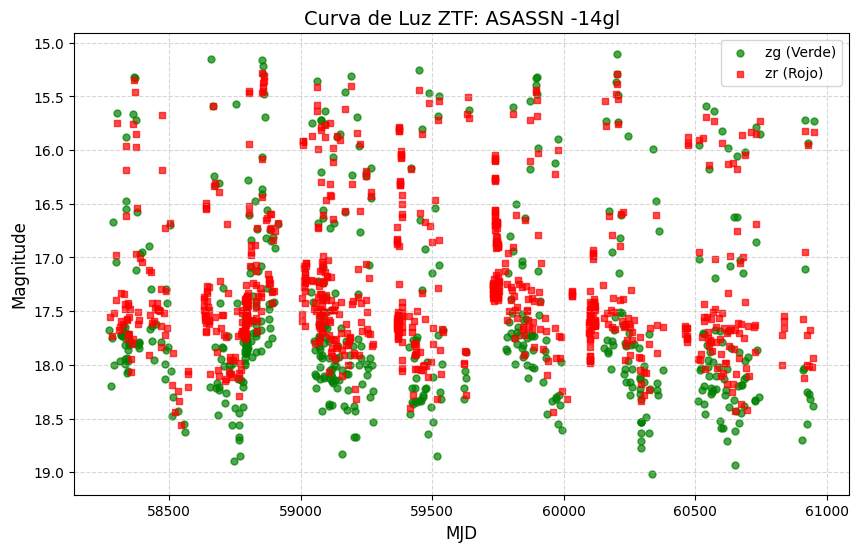

In [30]:
from ztfquery import lightcurve

df_mejores['Name'] = df_mejores['Name'].str.strip()

diccionario_oids = df_mejores.groupby('Name')['oid'].apply(list).to_dict()

nombre_prueba = "ASASSN -14gl" 

if nombre_prueba in diccionario_oids:
    lista_oids = diccionario_oids[nombre_prueba]
    
    try:
        oids_como_texto = [str(oid) for oid in lista_oids]
        print("Consultando al servidor de IRSA...")
        
        lcq = lightcurve.LCQuery.from_id(oids_como_texto)
        df_curva = lcq.data 
        
        if df_curva is not None and not df_curva.empty:
            if str(df_curva.columns[0]).startswith('<'):
                print("Falla del servidor: IRSA devolvió HTML (Error 504).")
            else:
                print(f"Se descargaron {len(df_curva)} puntos.")
                
                print("\nDesglose por filtro:")
                for filtro, cantidad in df_curva['filtercode'].value_counts().items():
                    print(f"  - Filtro {filtro}: {cantidad} puntos")
                print("-" * 20)
                
                plot_lightcurve(df_curva, nombre_prueba)
        else:
            print(f"La tabla de {nombre_prueba} vino vacía.")
            
    except Exception as e:
        print(f" Error: {type(e).__name__} - {e}")

In [1]:
import pandas as pd
from astroquery.gaia import Gaia
import astropy.units as u
from astropy.coordinates import SkyCoord
import time

# Lee tu archivo
df = pd.read_csv("vamos_a_ver.csv")

errores_paralaje = []

print("Consultando a Gaia...")

for index, row in df.iterrows():
    try:
    
        ra = row['ra']
        dec = row['dec']
        
        # Creamos la coordenada
        coord = SkyCoord(ra=ra, dec=dec, unit=(u.degree, u.degree), frame='icrs')
        
        # Buscamos en Gaia en un radio de 2 arcsec
        job = Gaia.cone_search_async(coord, radius=u.Quantity(2, u.arcsec))
        resultados = job.get_results()
        
        if len(resultados) > 0:
            # Tomamos el error del paralaje del primer resultado (el más cercano)
            err = resultados['parallax_error'][0]
            errores_paralaje.append(err)
            print(f"[{index}] OK - Error: {err}")
        else:
            errores_paralaje.append(None)
            print(f"[{index}] Sin datos en Gaia.")
            
    except Exception as e:
        print(f"[{index}] Error en la consulta: {e}")
        errores_paralaje.append(None)
        
    # Pausa corta para no saturar el servidor de Gaia
    time.sleep(0.5)

# Agregamos la columna nueva al dataframe
df['parallax_error'] = errores_paralaje

# Guardamos el archivo actualizado
df.to_csv("archivo_con_error_paralaje.csv", index=False)

print("Proceso terminado. Archivo guardado.")

The archive is unstable and may perform below expectations. If launching multiple, consecutive, heavy queries through Python, please space them out (e.g., using sleep(1)) to avoid overloading the system. Please contact the Gaia helpdesk in case of questions (https://www.cosmos.esa.int/web/gaia/gaia-helpdesk). Workaround solutions for the issues following the December 2025 infrastructure upgrade: https://www.cosmos.esa.int/web/gaia/news#WorkaroundArchive

The GACS will be under maintenance on 15 April from 11:00 to 13:00 CEST approximately, for the upgrade to version 3.12.0. Apologies for the inconveniences.
Consultando a Gaia...
INFO: Query finished. [astroquery.utils.tap.core]
[0] OK - Error: 0.06058749556541443
INFO: Query finished. [astroquery.utils.tap.core]
[1] OK - Error: 0.06058749556541443
INFO: Query finished. [astroquery.utils.tap.core]
[2] OK - Error: 0.08350905776023865
INFO: Query finished. [astroquery.utils.tap.core]
[3] OK - Error: 0.08350905776023865
INFO: Query finishe

KeyboardInterrupt: 

In [3]:
import pandas as pd
from astropy.table import Table
import astropy.units as u
from astroquery.xmatch import XMatch

df = pd.read_csv("vamos_a_ver.csv")

df_limpio = df.dropna(subset=['ra', 'dec']).copy()

tabla_local = Table.from_pandas(df_limpio)

print("Enviando tabla a VizieR para crossmatch masivo con Gaia DR3...")

resultado = XMatch.query(cat1=tabla_local, cat2='vizier:I/355/gaiadr3',  max_distance=2 * u.arcsec,  colRA1='ra',  colDec1='dec')

df_xmatch = resultado.to_pandas()

df_solo_error = df_xmatch[['ra', 'dec', 'e_Plx']].copy()
df_solo_error.rename(columns={'e_Plx': 'parallax_error'}, inplace=True)

df_final = pd.merge(df, df_solo_error, on=['ra', 'dec'], how='left')
df_final.to_csv("archivo_con_error_paralaje.csv", index=False)

print("Archivo guardado con éxito.")

Enviando tabla a VizieR para crossmatch masivo con Gaia DR3...
Crossmatch listo. 528 coincidencias encontradas.
Archivo guardado con éxito.


In [69]:
import pandas as pd

bh = pd.read_csv('DN_seleccionadas.csv')
bh_pepe = bh.drop(columns=['Unnamed: 0'])
bh_pepe.to_csv('kk.csv', index = False)

KeyError: "['Unnamed: 0'] not found in axis"

In [26]:
for col in bh.columns:
    print(repr(col))

'Name'
'Source_id'
'ra'
'dec'
'P_orb'
'Parallax'
'Parallax_error'
'Tipo_CV'
'Tipo_DN'
'filtercode'
'Puntos_totales'
'Incl'
'oid'


In [70]:
import pandas as pd
pc = pd.read_csv('DN_seleccionadas.csv')
pc.rename(columns={'ra': 'rammm', 'dec':'decmmm'}, inplace = True)
pc

,Name,Source_id,rammm,decmmm,P_orb,Parallax,Parallax_error,Tipo_CV,Tipo_DN,filtercode,Puntos_totales,Incl,oid
0,ASASSN -13cl,1800410845504429696,324.521009,26.638831,0.20220,0.748635,0.0992,DN,UG,zg,1142,NaN,643110400006329
1,ASASSN -13cl,1800410845504429696,324.521017,26.638833,0.20220,0.748635,0.0992,DN,UG,zr,1438,NaN,643210400010289
2,ASASSN -13cx,384460943781889024,0.593272,42.703687,0.07965,2.486948,0.1339,DN,SU,zg,706,NaN,694116400006569
3,ASASSN -13cx,384460943781889024,0.593280,42.703673,0.07965,2.486948,0.1339,DN,SU,zr,1002,NaN,694216400037184
4,ASASSN -14gl,352941828064202368,31.251601,46.093909,0.07000,0.995465,0.1098,DN,SU,zg,563,NaN,739107400008865
...,...,...,...,...,...,...,...,...,...,...,...,...,...
129,V* WW Cet,2427474150870397056,2.853268,-11.478568,0.17580,4.540628,0.0296,DN,ZC,zr,393,54.0,345208400006531
130,V* WY Tri,325028217130868480,36.251959,32.998780,0.07590,1.972178,0.1065,DN,SU,zg,599,NaN,653108100001524
131,V* WY Tri,325028217130868480,36.251961,32.998777,0.07590,1.972178,0.1065,DN,SU,zr,944,NaN,653208100002613
132,VSX J040659.7+005244,3258480812896290560,61.749231,0.878841,0.07730,2.185922,0.1329,DN,SU,zg,475,NaN,405116200000779


In [71]:
from astroquery.simbad import Simbad

# pedir que devuelva coordenadas
Simbad.add_votable_fields("ra", "dec")

result = Simbad.query_objects(pc["Name"].tolist())

In [72]:
df_coords = result.to_pandas()

In [73]:
df_coords

,main_id,ra,dec,coo_err_maj,coo_err_min,coo_err_angle,coo_wavelength,coo_bibcode,plx_value,plx_err,otype,user_specified_id,object_number_id
0,ASASSN -13cl,324.521009,26.638799,0.0539,0.0578,90,O,2020yCat.1350....0G,0.7486,0.0992,CV*,ASASSN -13cl,1
1,ASASSN -13cl,324.521009,26.638799,0.0539,0.0578,90,O,2020yCat.1350....0G,0.7486,0.0992,CV*,ASASSN -13cl,2
2,ASASSN -13cx,0.593190,42.703746,0.1043,0.0737,90,O,2020yCat.1350....0G,2.4869,0.1339,CV*,ASASSN -13cx,3
3,ASASSN -13cx,0.593190,42.703746,0.1043,0.0737,90,O,2020yCat.1350....0G,2.4869,0.1339,CV*,ASASSN -13cx,4
4,ASASSN -14gl,31.251496,46.093899,0.3169,0.1548,90,O,2018yCat.1345....0G,NaN,NaN,CV*,ASASSN -14gl,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...
129,V* WW Cet,2.853219,-11.478668,0.0240,0.0181,90,O,2020yCat.1350....0G,4.5406,0.0296,CV*,V* WW Cet,130
130,V* WY Tri,36.252021,32.998840,0.1157,0.1070,90,O,2018yCat.1345....0G,2.0392,0.1339,CV*,V* WY Tri,131
131,V* WY Tri,36.252021,32.998840,0.1157,0.1070,90,O,2018yCat.1345....0G,2.0392,0.1339,CV*,V* WY Tri,132
132,VSX J040659.7+005244,61.749279,0.878913,0.1082,0.0789,90,O,2020yCat.1350....0G,2.1859,0.1329,CV*,VSX J040659.7+005244,133


In [74]:
df_final = pc.merge(
    df_coords[["main_id", "ra", "dec"]],
    left_on="Name",
    right_on="main_id",
    how="left"
)

In [75]:
df_final = df_final.drop(columns=['main_id'])
df_final = df_final.drop(columns=['rammm'])
df_final = df_final.drop(columns=['decmmm'])

In [76]:
df_final = df_final[['Name','Source_id', 'ra','dec', 'P_orb', 'Parallax', 'Parallax_error', 'Tipo_CV', 'Tipo_DN','filtercode', 'Puntos_totales', 'Incl','oid']]

In [77]:
df_final = df_final.drop_duplicates(subset=["oid"])

In [78]:
df_final

,Name,Source_id,ra,dec,P_orb,Parallax,Parallax_error,Tipo_CV,Tipo_DN,filtercode,Puntos_totales,Incl,oid
0,ASASSN -13cl,1800410845504429696,324.521009,26.638799,0.20220,0.748635,0.0992,DN,UG,zg,1142,NaN,643110400006329
2,ASASSN -13cl,1800410845504429696,324.521009,26.638799,0.20220,0.748635,0.0992,DN,UG,zr,1438,NaN,643210400010289
4,ASASSN -13cx,384460943781889024,0.593190,42.703746,0.07965,2.486948,0.1339,DN,SU,zg,706,NaN,694116400006569
6,ASASSN -13cx,384460943781889024,0.593190,42.703746,0.07965,2.486948,0.1339,DN,SU,zr,1002,NaN,694216400037184
8,ASASSN -14gl,352941828064202368,31.251496,46.093899,0.07000,0.995465,0.1098,DN,SU,zg,563,NaN,739107400008865
...,...,...,...,...,...,...,...,...,...,...,...,...,...
266,V* WW Cet,2427474150870397056,2.853219,-11.478668,0.17580,4.540628,0.0296,DN,ZC,zr,393,54.0,345208400006531
268,V* WY Tri,325028217130868480,36.252021,32.998840,0.07590,1.972178,0.1065,DN,SU,zg,599,NaN,653108100001524
270,V* WY Tri,325028217130868480,36.252021,32.998840,0.07590,1.972178,0.1065,DN,SU,zr,944,NaN,653208100002613
272,VSX J040659.7+005244,3258480812896290560,61.749279,0.878913,0.07730,2.185922,0.1329,DN,SU,zg,475,NaN,405116200000779


In [4]:
import pandas as pd

bh = pd.read_csv('DN_seleccionadas.csv')
bh = bh.drop(index=[68,69])
bh.to_csv('xdd.csv')

In [6]:
import pandas as pd

bh = pd.read_csv('xdd.csv')
bh_cf = bh.drop(columns=['Unnamed: 0'])
bh_cf.to_csv('DN_seleccionadas2.csv', index = False)

In [10]:
import pandas as pd

df = pd.read_csv('DN_seleccionadas.csv')
df = df.drop(columns=['Source_id', 'Parallax_error', 'Tipo_CV','filtercode', 'Puntos_totales','oid'])
df['P_orb'] = df['P_orb'] * 24
df = df.drop_duplicates(subset='Name')
df['Parallax'] = 1000/df['Parallax'] 

df.to_latex("tabla_objetos.tex", index=False)

In [3]:
import pandas as pd
df = pd.read_csv('inclinaciones_MC.csv')
df = df.drop_duplicates(subset='Name')
df.to_csv('inclinaciones_MC.csv')